# AlphaMissense · Opus R1 · Evolutionary constraint at the variant position

Run all cells in order. This notebook downloads the public inputs, computes the axis and performance, draws the controls, and evaluates the decision. All analysis code is contained below.

Python 3.11; packages: `numpy==1.26.4 pandas==2.2.2 scipy==1.13.1 matplotlib==3.9.4 pyarrow==16.1.0 biopython==1.85 pyhmmer==0.12.1`. Install these into the notebook kernel environment before running.


## 1. Data source / acquisition

The fixed panel contains 73 ProteinGym assays of 64 human proteins. Assay identifiers and accessions below define the selection independently of outcomes. ProteinGym v1.3 provides experimental measurements and the pinned metadata commit provides target sequences and alignment metadata. AlphaMissense provides its published amino-acid substitution scores. Downloaded files are checked by size and SHA-256 before reuse.

The public reference bundle supplies pinned Swiss-Prot canonical sequences for mapping assay-local positions to full-protein score positions. Residue analyses also use the selected raw ProteinGym alignments or AlphaFold structure files. Only the specified raw members are extracted. The data providers are [UniProt](https://www.uniprot.org/), [ProteinGym](https://proteingym.org/), and [AlphaFold DB](https://alphafold.ebi.ac.uk/).


In [1]:
ANALYSIS_ID='am-opus-r1/test-01'
RUN=1
AXIS=1
SOURCES={'metadata': {'filename': 'DMS_substitutions.csv',
              'url': 'https://raw.githubusercontent.com/OATML-Markslab/ProteinGym/144fe22b07dfaeec2b366f2346203a9838a55b4c/reference_files/DMS_substitutions.csv',
              'bytes': 208734,
              'sha256': 'a8f498011532a74aa9fe556a50555a75e928c5837d19c06a87592ae04049b308'},
 'experiments': {'filename': 'DMS_ProteinGym_v1.3_substitutions.zip',
                 'url': 'https://marks.hms.harvard.edu/proteingym/ProteinGym_v1.3/DMS_ProteinGym_substitutions.zip',
                 'bytes': 43021128,
                 'sha256': '3a83766254ac9ac9984ec25cb73c6e010ea4418f5e35f143933e6b6e6473b921'},
 'scores': {'filename': 'AlphaMissense_aa_substitutions.tsv.gz',
            'url': 'https://storage.googleapis.com/dm_alphamissense/AlphaMissense_aa_substitutions.tsv.gz',
            'bytes': 1207278510,
            'sha256': 'bc18d954a9aa6b9efab8e40d6d1912e32b774906cd3846a1f51066588e9c176d'},
 'reference_bundle': {'filename': 'alphamissense-inputs.zip',
                      'url': 'https://github.com/shreyjain11/SPECTRAagent/releases/download/notebook-inputs-2026-11-08-v1/alphamissense-inputs.zip',
                      'bytes': 998791045,
                      'sha256': '9088ab792238292f8f1ec5587f95876e0951a06484795266362d51b12641228c'}}
PANEL=[{'assay': 'A4_HUMAN_Seuma_2022', 'acc': 'P05067'},
 {'assay': 'ACE2_HUMAN_Chan_2020', 'acc': 'Q9BYF1'},
 {'assay': 'ADRB2_HUMAN_Jones_2020', 'acc': 'P07550'},
 {'assay': 'AICDA_HUMAN_Gajula_2014_3cycles', 'acc': 'Q9GZX7'},
 {'assay': 'B2L11_HUMAN_Dutta_2010_binding-Mcl-1', 'acc': 'O43521'},
 {'assay': 'BRCA1_HUMAN_Findlay_2018', 'acc': 'P38398'},
 {'assay': 'BRCA2_HUMAN_Erwood_2022_HEK293T', 'acc': 'P51587'},
 {'assay': 'CALM1_HUMAN_Weile_2017', 'acc': 'P0DP23'},
 {'assay': 'CAR11_HUMAN_Meitlis_2020_gof', 'acc': 'Q9BXL7'},
 {'assay': 'CAR11_HUMAN_Meitlis_2020_lof', 'acc': 'Q9BXL7'},
 {'assay': 'CBPA2_HUMAN_Tsuboyama_2023_1O6X', 'acc': 'P48052'},
 {'assay': 'CBS_HUMAN_Sun_2020', 'acc': 'P35520'},
 {'assay': 'CBX4_HUMAN_Tsuboyama_2023_2K28', 'acc': 'O00257'},
 {'assay': 'CCR5_HUMAN_Gill_2023', 'acc': 'P51681'},
 {'assay': 'CD19_HUMAN_Klesmith_2019_FMC_singles', 'acc': 'P15391'},
 {'assay': 'CP2C9_HUMAN_Amorosi_2021_abundance', 'acc': 'P11712'},
 {'assay': 'CP2C9_HUMAN_Amorosi_2021_activity', 'acc': 'P11712'},
 {'assay': 'DLG4_HUMAN_Faure_2021', 'acc': 'P78352'},
 {'assay': 'DNJA1_HUMAN_Tsuboyama_2023_2LO1', 'acc': 'P31689'},
 {'assay': 'EPHB2_HUMAN_Tsuboyama_2023_1F0M', 'acc': 'P29323'},
 {'assay': 'ERBB2_HUMAN_Elazar_2016', 'acc': 'P04626'},
 {'assay': 'FKBP3_HUMAN_Tsuboyama_2023_2KFV', 'acc': 'Q00688'},
 {'assay': 'GDIA_HUMAN_Silverstein_2021', 'acc': 'P31150'},
 {'assay': 'GRB2_HUMAN_Faure_2021', 'acc': 'P62993'},
 {'assay': 'HEM3_HUMAN_Loggerenberg_2023', 'acc': 'P08397'},
 {'assay': 'HMDH_HUMAN_Jiang_2019', 'acc': 'P04035'},
 {'assay': 'HXK4_HUMAN_Gersing_2022_activity', 'acc': 'P35557'},
 {'assay': 'HXK4_HUMAN_Gersing_2023_abundance', 'acc': 'P35557'},
 {'assay': 'KCNH2_HUMAN_Kozek_2020', 'acc': 'Q12809'},
 {'assay': 'LYAM1_HUMAN_Elazar_2016', 'acc': 'P14151'},
 {'assay': 'MET_HUMAN_Estevam_2023', 'acc': 'P08581'},
 {'assay': 'MK01_HUMAN_Brenan_2016', 'acc': 'P28482'},
 {'assay': 'MSH2_HUMAN_Jia_2020', 'acc': 'P43246'},
 {'assay': 'MTHR_HUMAN_Weile_2021', 'acc': 'P42898'},
 {'assay': 'NPC1_HUMAN_Erwood_2022_HEK293T', 'acc': 'O15118'},
 {'assay': 'NPC1_HUMAN_Erwood_2022_RPE1', 'acc': 'O15118'},
 {'assay': 'NUD15_HUMAN_Suiter_2020', 'acc': 'Q9NV35'},
 {'assay': 'OBSCN_HUMAN_Tsuboyama_2023_1V1C', 'acc': 'Q5VST9'},
 {'assay': 'OPSD_HUMAN_Wan_2019', 'acc': 'P08100'},
 {'assay': 'OTC_HUMAN_Lo_2023', 'acc': 'P00480'},
 {'assay': 'OTU7A_HUMAN_Tsuboyama_2023_2L2D', 'acc': 'Q8TE49'},
 {'assay': 'P53_HUMAN_Kotler_2018', 'acc': 'P04637'},
 {'assay': 'PAI1_HUMAN_Huttinger_2021', 'acc': 'P05121'},
 {'assay': 'PIN1_HUMAN_Tsuboyama_2023_1I6C', 'acc': 'Q13526'},
 {'assay': 'PPARG_HUMAN_Majithia_2016', 'acc': 'P37231'},
 {'assay': 'PPM1D_HUMAN_Miller_2022', 'acc': 'O15297'},
 {'assay': 'PR40A_HUMAN_Tsuboyama_2023_1UZC', 'acc': 'O75400'},
 {'assay': 'PRKN_HUMAN_Clausen_2023', 'acc': 'O60260'},
 {'assay': 'PTEN_HUMAN_Matreyek_2021', 'acc': 'P60484'},
 {'assay': 'PTEN_HUMAN_Mighell_2018', 'acc': 'P60484'},
 {'assay': 'RAF1_HUMAN_Zinkus-Boltz_2019', 'acc': 'P04049'},
 {'assay': 'RASH_HUMAN_Bandaru_2017', 'acc': 'P01112'},
 {'assay': 'RD23A_HUMAN_Tsuboyama_2023_1IFY', 'acc': 'P54725'},
 {'assay': 'S22A1_HUMAN_Yee_2023_abundance', 'acc': 'O15245'},
 {'assay': 'S22A1_HUMAN_Yee_2023_activity', 'acc': 'O15245'},
 {'assay': 'SC6A4_HUMAN_Young_2021', 'acc': 'P31645'},
 {'assay': 'SCN5A_HUMAN_Glazer_2019', 'acc': 'Q14524'},
 {'assay': 'SERC_HUMAN_Xie_2023', 'acc': 'Q9Y617'},
 {'assay': 'SHOC2_HUMAN_Kwon_2022', 'acc': 'Q9UQ13'},
 {'assay': 'SOX30_HUMAN_Tsuboyama_2023_7JJK', 'acc': 'O94993'},
 {'assay': 'SRC_HUMAN_Ahler_2019', 'acc': 'P12931'},
 {'assay': 'SRC_HUMAN_Chakraborty_2023_binding-DAS_25uM', 'acc': 'P12931'},
 {'assay': 'SRC_HUMAN_Nguyen_2022', 'acc': 'P12931'},
 {'assay': 'SUMO1_HUMAN_Weile_2017', 'acc': 'P63165'},
 {'assay': 'TADBP_HUMAN_Bolognesi_2019', 'acc': 'Q13148'},
 {'assay': 'TPK1_HUMAN_Weile_2017', 'acc': 'Q9H3S4'},
 {'assay': 'TPMT_HUMAN_Matreyek_2018', 'acc': 'P51580'},
 {'assay': 'UBC9_HUMAN_Weile_2017', 'acc': 'P63279'},
 {'assay': 'UBE4B_HUMAN_Tsuboyama_2023_3L1X', 'acc': 'O95155'},
 {'assay': 'UBR5_HUMAN_Tsuboyama_2023_1I2T', 'acc': 'O95071'},
 {'assay': 'VKOR1_HUMAN_Chiasson_2020_abundance', 'acc': 'Q9BQB6'},
 {'assay': 'VKOR1_HUMAN_Chiasson_2020_activity', 'acc': 'Q9BQB6'},
 {'assay': 'YAP1_HUMAN_Araya_2012', 'acc': 'P46937'}]

from pathlib import Path
from collections import Counter
import concurrent.futures, csv, gzip, hashlib, io, json, os, platform, shutil, tarfile, time, urllib.request, zipfile
import numpy as np
import pandas as pd
import scipy
from scipy.stats import spearmanr, wilcoxon
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

INPUT=Path(os.environ.get('AM_OPUS_INPUTS', Path.cwd()/'inputs'))
INPUT.mkdir(parents=True,exist_ok=True)
OUT=Path.cwd()/f'{ANALYSIS_ID.replace("/","-")}-outputs'
OUT.mkdir(parents=True,exist_ok=True)
AA='ACDEFGHIKLMNPQRSTVWY'
pd.set_option('display.max_columns',30)
pd.set_option('display.max_rows',90)

def show_figure(figure):
    buffer=io.BytesIO()
    figure.savefig(buffer,format='png',dpi=130,bbox_inches='tight')
    display(Image(data=buffer.getvalue()))
    plt.close(figure)

def sha256(path):
    digest=hashlib.sha256()
    with open(path,'rb') as handle:
        for block in iter(lambda:handle.read(8*1024*1024),b''):digest.update(block)
    return digest.hexdigest()

def acquire(record):
    path=INPUT/record['filename']
    if path.is_file() and path.stat().st_size==record['bytes'] and sha256(path)==record['sha256']:
        return path
    part=path.with_name(path.name+f'.{os.getpid()}.part')
    with urllib.request.urlopen(record['url'],timeout=120) as response,open(part,'wb') as target:
        shutil.copyfileobj(response,target,8*1024*1024)
    assert part.stat().st_size==record['bytes'],record['filename']
    assert sha256(part)==record['sha256'],record['filename']
    part.replace(path)
    return path

def extract_member(archive,record):
    destination=INPUT/Path(record['member']).name
    if destination.exists() and sha256(destination)==record['sha256']:return destination
    temporary=destination.with_name(destination.name+f'.{os.getpid()}.part')
    with zipfile.ZipFile(archive) as bundle,bundle.open(record['member']) as source,open(temporary,'wb') as target:
        shutil.copyfileobj(source,target,8*1024*1024)
    assert temporary.stat().st_size==record['bytes']
    assert sha256(temporary)==record['sha256']
    temporary.replace(destination)
    return destination

display(pd.DataFrame(SOURCES).T[['filename','bytes','sha256','url']])
paths={name:acquire(record) for name,record in SOURCES.items()}
print('Source files downloaded or verified:',len(paths))
print('Python',platform.python_version(),'NumPy',np.__version__,'pandas',pd.__version__,'SciPy',scipy.__version__)


,filename,bytes,sha256,url
metadata,DMS_substitutions.csv,208734,a8f498011532a74aa9fe556a50555a75e928c5837d19c0...,https://raw.githubusercontent.com/OATML-Marksl...
experiments,DMS_ProteinGym_v1.3_substitutions.zip,43021128,3a83766254ac9ac9984ec25cb73c6e010ea4418f5e35f1...,https://marks.hms.harvard.edu/proteingym/Prote...
scores,AlphaMissense_aa_substitutions.tsv.gz,1207278510,bc18d954a9aa6b9efab8e40d6d1912e32b774906cd3846...,https://storage.googleapis.com/dm_alphamissens...
reference_bundle,alphamissense-inputs.zip,998791045,9088ab792238292f8f1ec5587f95876e0951a064847952...,https://github.com/shreyjain11/SPECTRAagent/re...


Source files downloaded or verified: 4
Python 3.11.13 NumPy 1.26.4 pandas 2.2.2 SciPy 1.13.1


In [2]:
swissprot_path=extract_member(paths["reference_bundle"],{'bytes': 93706469,
 'member': 'am-opus-r1/data/uniprot_sprot.fasta.gz',
 'sha256': 'b774748a050fd3de0bf2ad49b359ed59a2c2b02c89df3fe0679fafa446751794'})
print(swissprot_path.name)


uniprot_sprot.fasta.gz


## 2. Data processing

Read the raw assay CSVs. Retain single amino-acid substitutions with numeric experimental measurements and a matching wild-type residue in the declared target sequence. Every exclusion count is displayed; no saved per-variant analysis table is used.


In [3]:
panel=pd.DataFrame(PANEL)
metadata=pd.read_csv(paths['metadata']).rename(columns={'DMS_id':'assay'})
metadata=panel.merge(metadata,on='assay',validate='one_to_one')
assert len(metadata)==len(panel)
assert metadata.groupby('acc').target_seq.nunique().max()==1
from Bio import SeqIO
canonical_sequences={}
wanted_accessions=set(panel.acc)
with gzip.open(swissprot_path,'rt') as handle:
    for record in SeqIO.parse(handle,'fasta'):
        accession=record.id.split('|')[1]
        if accession in wanted_accessions:canonical_sequences[accession]=str(record.seq)
assert wanted_accessions<=set(canonical_sequences),'A panel accession is absent from the pinned Swiss-Prot FASTA'
variant_tables=[]; processing_counts=[]
with zipfile.ZipFile(paths['experiments']) as archive:
    for record in metadata.itertuples(index=False):
        member=f'DMS_ProteinGym_substitutions/{record.assay}.csv'
        with archive.open(member) as handle:raw=pd.read_csv(handle)
        frame=raw.loc[raw.mutant.str.fullmatch(r'[ACDEFGHIKLMNPQRSTVWY][0-9]+[ACDEFGHIKLMNPQRSTVWY]',na=False),['mutant','DMS_score']].copy()
        frame['DMS_score']=pd.to_numeric(frame.DMS_score,errors='coerce')
        frame=frame.dropna(subset=['DMS_score'])
        frame['position']=frame.mutant.str[1:-1].astype(int)
        frame['wt']=frame.mutant.str[0];frame['alt']=frame.mutant.str[-1]
        valid=[1<=p<=len(record.target_seq) and record.target_seq[p-1]==w for p,w in zip(frame.position,frame.wt)]
        mismatches=int((~np.asarray(valid)).sum())
        frame=frame.loc[valid].copy()
        assert not frame.mutant.duplicated().any(),record.assay
        frame['assay']=record.assay;frame['acc']=record.acc
        variant_tables.append(frame)
        processing_counts.append(dict(assay=record.assay,raw_rows=len(raw),single_valid_substitutions=len(frame),target_residue_mismatches=mismatches))
variants=pd.concat(variant_tables,ignore_index=True)
variants=variants.merge(metadata[['assay','UniProt_ID','coarse_selection_type','MSA_filename','MSA_start','MSA_end','MSA_len','MSA_N_eff','MSA_Neff_L']],on='assay',validate='many_to_one')
processing=pd.DataFrame(processing_counts)
processing.to_csv(OUT/'input_processing_counts.csv',index=False)
display(processing)
print('Variants before released-score join:',len(variants),'Assays:',variants.assay.nunique(),'Proteins:',variants.acc.nunique())


,assay,raw_rows,single_valid_substitutions,target_residue_mismatches
0,A4_HUMAN_Seuma_2022,14811,796,0
1,ACE2_HUMAN_Chan_2020,2223,2223,0
2,ADRB2_HUMAN_Jones_2020,7800,7800,0
3,AICDA_HUMAN_Gajula_2014_3cycles,209,209,0
4,B2L11_HUMAN_Dutta_2010_binding-Mcl-1,170,170,0
5,BRCA1_HUMAN_Findlay_2018,1837,1837,0
6,BRCA2_HUMAN_Erwood_2022_HEK293T,265,265,0
7,CALM1_HUMAN_Weile_2017,1813,1813,0
8,CAR11_HUMAN_Meitlis_2020_gof,2374,2374,0
9,CAR11_HUMAN_Meitlis_2020_lof,2395,2395,0


Variants before released-score join: 273135 Assays: 73 Proteins: 64


Search each target sequence against the checksum-pinned Swiss-Prot FASTA with phmmer (inclusion E-value 0.001, first 8,000 reported hits). For every aligned query position, count reference residues and calculate Shannon entropy. Coverage divides non-gap aligned residues by the number of reported hits; overlapping domains are counted as aligned. The same residue counts will supply the PSSM control.


In [4]:
import pyhmmer
from pyhmmer.easel import Alphabet, TextSequence, SequenceFile
from pyhmmer.plan7 import Pipeline

assert pyhmmer.__version__=='0.12.1'
alphabet=Alphabet.amino()
with SequenceFile(swissprot_path,digital=True,alphabet=alphabet) as source:
    sequence_database=source.read_block()
print('Swiss-Prot reference sequences:',len(sequence_database))

def position_profile(record):
    query=TextSequence(name=record.acc.encode(),sequence=record.target_seq).digitize(alphabet)
    hits=Pipeline(alphabet,incE=1e-3).search_seq(query,sequence_database)
    counts=[Counter() for _ in record.target_seq]
    for hit_number,hit in enumerate(hits):
        if hit_number>=8000:break
        for domain in hit.domains:
            alignment=domain.alignment
            position=alignment.hmm_from-1
            for query_letter,reference_letter in zip(alignment.hmm_sequence,alignment.target_sequence):
                if query_letter!='.':
                    if 0<=position<len(counts) and reference_letter not in '-.':
                        counts[position][reference_letter.upper()]+=1
                    position+=1
    rows=[]
    for position,counter in enumerate(counts,1):
        coverage=sum(counter.values())
        probabilities=np.asarray(list(counter.values()),dtype=float)/coverage if coverage else np.array([])
        entropy=float(-(probabilities*np.log2(probabilities)).sum()) if coverage else np.nan
        rows.append(dict(acc=record.acc,position=position,cov=coverage,cov_frac=coverage/max(len(hits),1),entropy=entropy,total_hits=len(hits),**{f'count_{letter}':counter[letter] for letter in AA}))
    return rows

proteins=list(metadata.drop_duplicates('acc').itertuples(index=False))
profile_rows=[]
with concurrent.futures.ThreadPoolExecutor(max_workers=2) as pool:
    for number,rows in enumerate(pool.map(position_profile,proteins),1):
        profile_rows.extend(rows)
        if number%8==0:print('Protein searches completed:',number,'/',len(proteins),flush=True)
profiles=pd.DataFrame(profile_rows)
profiles.to_parquet(OUT/'residue_profiles.parquet',index=False)
variants=variants.merge(profiles,on=['acc','position'],validate='many_to_one')
variants['constraint']=-variants.entropy
print('Recalculated residue profiles:',len(profiles))


Swiss-Prot reference sequences: 575503


Protein searches completed: 8 / 64


Protein searches completed: 16 / 64


Protein searches completed: 24 / 64


Protein searches completed: 32 / 64


Protein searches completed: 40 / 64


Protein searches completed: 48 / 64


Protein searches completed: 56 / 64


Protein searches completed: 64 / 64


Recalculated residue profiles: 32071


## 3. Axis definition and level construction


Constraint is the negative Shannon entropy of the aligned residue distribution. Higher values mean more conserved positions. Within each assay, unique positions are ranked by this feature, with position as the deterministic tie breaker. Positions are split into three levels, then five levels for a denser check. All substitutions at one position receive the same level.


In [5]:
def rank_position_levels(frame,feature,nlevels):
    rows=[]
    for assay,group in frame.groupby('assay',sort=True):
        positions=group[['position',feature]].dropna().drop_duplicates('position')
        if positions[feature].nunique()<nlevels:continue
        positions=positions.sort_values([feature,'position'],kind='stable')
        positions['level']=pd.qcut(positions[feature].rank(method='first'),nlevels,labels=False)
        group=group.merge(positions[['position','level']],on='position',how='inner',validate='many_to_one')
        group['scheme']=f'{nlevels} levels';rows.append(group)
    return pd.concat(rows,ignore_index=True)

if RUN==1:
    discovery={acc for acc in variants.acc.unique() if int(hashlib.md5(acc.encode()).hexdigest(),16)%2==0}
else:
    accessions=np.array(sorted(variants.acc.unique()))
    if AXIS==1:accessions=np.array(sorted(variants.loc[variants.plddt.notna(),'acc'].unique()))
    np.random.default_rng(7).shuffle(accessions)
    discovery=set(accessions[:len(accessions)//2])
variants['split']=np.where(variants.acc.isin(discovery),'discovery','confirmation')

FEATURE='constraint'
AXIS_LABEL='Evolutionary constraint at the variant position'+' (low → high)'
level_members=pd.concat([rank_position_levels(variants,FEATURE,number) for number in [3,5]],ignore_index=True)
LEVEL_LABELS={'3 levels':['Low','Middle','High'],'5 levels':['Q1','Q2','Q3','Q4','Q5']}
level_members[['scheme','assay','acc','mutant','position',FEATURE,'level','split']].to_csv(OUT/'level_membership.csv.gz',index=False)
display(level_members.groupby(['scheme','level']).agg(variants=('mutant','size'),feature_mean=(FEATURE,'mean')))


variants  feature_mean
scheme   level                        
3 levels 0         91644     -3.078502
         1         90818     -2.276873
         2         90503     -1.091426
5 levels 0         55488     -3.235874
         1         54741     -2.763886
         2         54304     -2.277862
         3         54219     -1.693841
         4         54213     -0.761795

## 4. Model results or released scores

Read the downloaded official AlphaMissense table and align each assay target to its pinned Swiss-Prot canonical sequence, then join on UniProt accession plus the mapped full-protein amino-acid substitution. The code displays mapping methods and excluded variants. AlphaMissense is used as released; this analysis does not fine-tune it. Performance is absolute Spearman correlation against each assay’s experimental scores, so assays with opposite effect conventions remain comparable.


In [6]:
# Read the published AlphaMissense score table directly. No model fitting occurs.
# Map assay-local numbering to the canonical sequence in the pinned Swiss-Prot FASTA.
wanted=set(variants.acc)
released=[]
with gzip.open(paths['scores'],'rt') as handle:
    for line in handle:
        if line.startswith('#'):continue
        header=line.rstrip('\n').split('\t');break
    columns={name:header.index(name) for name in ['uniprot_id','protein_variant','am_pathogenicity']}
    for line in handle:
        accession=line.split('\t',1)[0]
        if accession not in wanted:continue
        values=line.rstrip('\n').split('\t')
        variant=values[columns['protein_variant']]
        released.append((accession,variant,float(values[columns['am_pathogenicity']])))
released=pd.DataFrame(released,columns=['acc','am_variant','am_pathogenicity'])
assert not released.duplicated(['acc','am_variant']).any()
from Bio import Align
score_aligner=Align.PairwiseAligner(mode='local',match_score=2,mismatch_score=-1,open_gap_score=-10,extend_gap_score=-1)
variants['am_variant']=None
score_mapping=[]
for assay,group in variants.groupby('assay'):
    accession=group.acc.iloc[0]
    target=metadata.set_index('assay').loc[assay,'target_seq']
    reference=canonical_sequences[accession]
    offset=reference.find(target);position_map={}
    if offset>=0:
        position_map={position+1:offset+position+1 for position in range(len(target))}
        method='exact target substring in pinned Swiss-Prot canonical sequence'
    else:
        alignment=score_aligner.align(target,reference)[0]
        for (t0,t1),(r0,r1) in zip(*alignment.aligned):
            for k in range(t1-t0):position_map[t0+k+1]=r0+k+1
        method='local target-to-Swiss-Prot canonical sequence alignment'
    mapped=[]
    for position,wildtype,alternate in zip(group.position,group.wt,group.alt):
        canonical_position=position_map.get(position)
        mapped.append(f'{wildtype}{canonical_position}{alternate}' if canonical_position is not None and reference[canonical_position-1]==wildtype else None)
    variants.loc[group.index,'am_variant']=mapped
    score_mapping.append(dict(assay=assay,acc=accession,method=method,target_length=len(target),canonical_length=len(reference),mapped_variants=sum(value is not None for value in mapped),unmapped_variants=sum(value is None for value in mapped)))
mapping_table=pd.DataFrame(score_mapping)
mapping_table.to_csv(OUT/'released_score_position_mapping.csv',index=False)
display(mapping_table)
before=len(variants)
variants=variants.merge(released,on=['acc','am_variant'],how='inner',validate='many_to_one')
assert len(variants)>0
print('Published score join:',len(variants),'variants; missing scores:',before-len(variants))
display(variants.groupby('split').agg(variants=('mutant','size'),assays=('assay','nunique'),proteins=('acc','nunique')))


,assay,acc,method,target_length,canonical_length,mapped_variants,unmapped_variants
0,A4_HUMAN_Seuma_2022,P05067,exact target substring in pinned Swiss-Prot ca...,770,770,796,0
1,ACE2_HUMAN_Chan_2020,Q9BYF1,exact target substring in pinned Swiss-Prot ca...,805,805,2223,0
2,ADRB2_HUMAN_Jones_2020,P07550,exact target substring in pinned Swiss-Prot ca...,413,413,7800,0
3,AICDA_HUMAN_Gajula_2014_3cycles,Q9GZX7,exact target substring in pinned Swiss-Prot ca...,198,198,209,0
4,B2L11_HUMAN_Dutta_2010_binding-Mcl-1,O43521,exact target substring in pinned Swiss-Prot ca...,198,198,170,0
5,BRCA1_HUMAN_Findlay_2018,P38398,exact target substring in pinned Swiss-Prot ca...,1863,1863,1837,0
6,BRCA2_HUMAN_Erwood_2022_HEK293T,P51587,exact target substring in pinned Swiss-Prot ca...,3418,3418,265,0
7,CALM1_HUMAN_Weile_2017,P0DP23,exact target substring in pinned Swiss-Prot ca...,149,149,1813,0
8,CAR11_HUMAN_Meitlis_2020_gof,Q9BXL7,exact target substring in pinned Swiss-Prot ca...,1154,1154,2374,0
9,CAR11_HUMAN_Meitlis_2020_lof,Q9BXL7,exact target substring in pinned Swiss-Prot ca...,1154,1154,2395,0


Published score join: 273135 variants; missing scores: 0


,variants,assays,proteins
split,,,
confirmation,133682,35,30
discovery,139453,38,34


Calculate BLOSUM62 and a PSSM log-ratio control from the raw residue counts (one pseudocount per standard amino acid). Compute performance independently inside every assay and level, requiring at least 50 scored variants, more than five distinct experimental scores, and more than two distinct predictor values. Undefined correlations remain missing.


In [7]:
from Bio.Align import substitution_matrices
blosum=substitution_matrices.load('BLOSUM62')
variants['blosum']=[float(blosum[w,a]) for w,a in zip(variants.wt,variants.alt)]
counts=variants[[f'count_{letter}' for letter in AA]].to_numpy(dtype=float)
frequencies=(counts+1)/(counts.sum(axis=1,keepdims=True)+20)
aa_index={letter:index for index,letter in enumerate(AA)}
row=np.arange(len(variants))
variants['pssm']=np.log(frequencies[row,[aa_index[a] for a in variants.alt]]/frequencies[row,[aa_index[w] for w in variants.wt]])


In [8]:
def agreement(group,column):
    usable=group[[column,'DMS_score']].dropna()
    if len(usable)<50 or usable.DMS_score.nunique()<=5 or usable[column].nunique()<=2:return np.nan
    return abs(float(spearmanr(usable[column],usable.DMS_score).statistic))

def score_cells(members):
    scored=[]
    for (scheme,assay,level),group in members.groupby(['scheme','assay','level'],observed=True):
        row=dict(scheme=scheme,assay=assay,level=int(level),n=len(group),acc=group.acc.iloc[0],split=group.split.iloc[0],selection=group.coarse_selection_type.iloc[0],dms_std=group.DMS_score.std())
        for name,column in [('AM','am_pathogenicity'),('BLOSUM','blosum'),('PSSM','pssm')]:row[name]=agreement(group,column)
        for feature in ['constraint','cov_frac','total_hits','coverage','plddt']:
            if feature in group:row[feature]=group[feature].mean()
        scored.append(row)
    return pd.DataFrame(scored)

joined_members=level_members.merge(variants[['assay','mutant','am_pathogenicity','blosum','pssm']],on=['assay','mutant'],how='inner',validate='many_to_one')
scores=score_cells(joined_members)
if RUN==1:
    valid=[]
    for (scheme,assay),group in scores.groupby(['scheme','assay']):
        nlevels=int(scheme.split()[0])
        if len(group)==nlevels and group.AM.notna().all():valid.append((scheme,assay))
    scores=scores.set_index(['scheme','assay']).loc[valid].reset_index()
scores.to_csv(OUT/'assay_level_scores.csv',index=False)
joined_members.to_parquet(OUT/'variant_levels_scores.parquet',index=False)
display(scores.groupby(['scheme','level']).agg(assays=('assay','nunique'),variants=('n','sum'),AM=('AM','mean')))


assays  variants        AM
scheme   level                            
3 levels 0          70     91563  0.326581
         1          70     90760  0.439868
         2          70     90414  0.491763
5 levels 0          65     55109  0.314795
         1          65     54460  0.352602
         2          65     54014  0.450776
         3          65     53974  0.449791
         4          65     53920  0.483567

## 5. Curves and controls


Curves average within-assay correlations and show assay-bootstrap 95% intervals. Paired highest-minus-lowest effects use assays with both extremes for all three predictors. Controls show discovery and confirmation, removal of stability assays, experimental dynamic range, and a denser level construction where specified. Positive effects mean higher performance at the higher axis level.


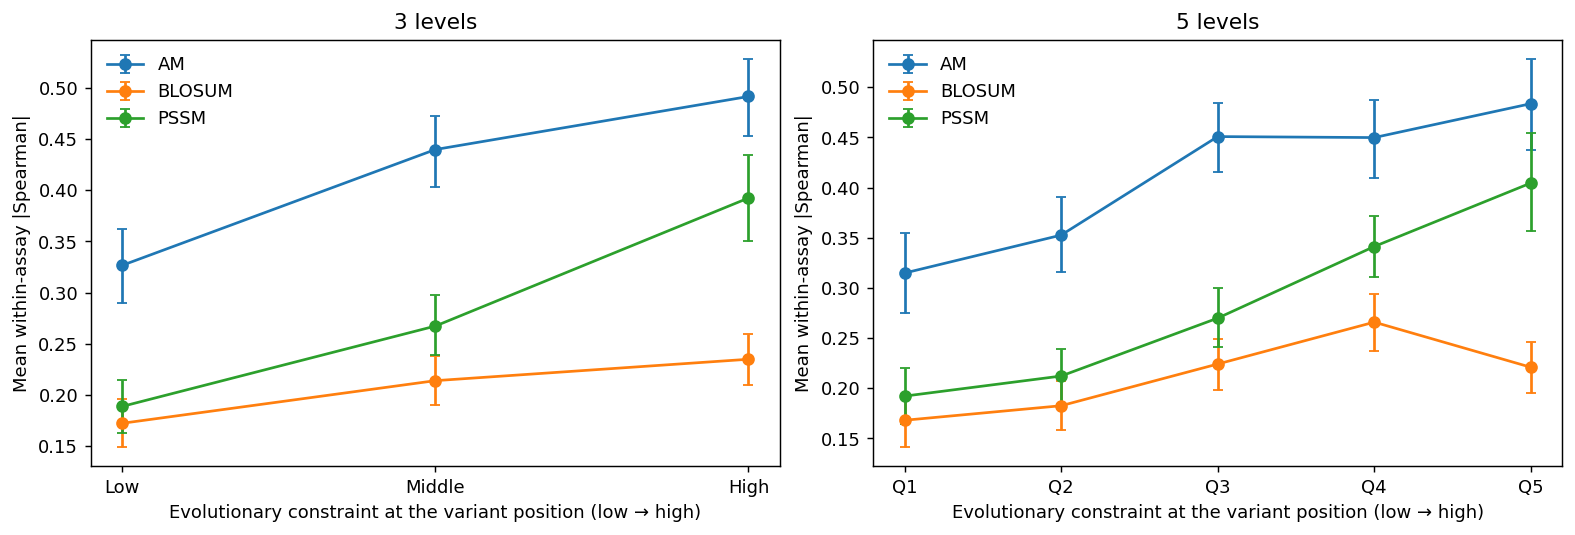

,scheme,method,level,mean,low,high,n_assays
0,3 levels,AM,0,0.326581,0.289828,0.362203,70
1,3 levels,AM,1,0.439868,0.403652,0.472922,70
2,3 levels,AM,2,0.491763,0.453048,0.528368,70
3,3 levels,BLOSUM,0,0.172115,0.149161,0.196227,70
4,3 levels,BLOSUM,1,0.213808,0.189745,0.238126,70
5,3 levels,BLOSUM,2,0.234749,0.209168,0.259476,70
6,3 levels,PSSM,0,0.188605,0.163097,0.214347,70
7,3 levels,PSSM,1,0.267210,0.239013,0.297803,70
8,3 levels,PSSM,2,0.392454,0.350062,0.434046,70
9,5 levels,AM,0,0.314795,0.274622,0.354720,65


,subset,scheme,comparison,mean,low,high,n_assays,wilcoxon_p
0,All,3 levels,AM,0.165182,0.124180,0.207340,70,6.311366e-09
1,All,3 levels,BLOSUM,0.062635,0.036472,0.087762,70,2.122386e-05
2,All,3 levels,PSSM,0.203848,0.158265,0.248007,70,5.632431e-10
3,All,3 levels,AM minus BLOSUM,0.102548,0.061320,0.144847,70,5.215575e-06
4,All,3 levels,AM minus PSSM,-0.038666,-0.076589,0.001012,70,4.198857e-02
5,All,5 levels,AM,0.172351,0.116713,0.224954,63,7.972433e-07
6,All,5 levels,BLOSUM,0.050675,0.021166,0.080522,63,1.066243e-03
7,All,5 levels,PSSM,0.209165,0.156055,0.263453,63,1.559534e-08
8,All,5 levels,AM minus BLOSUM,0.121676,0.068310,0.175013,63,8.034926e-05
9,All,5 levels,AM minus PSSM,-0.036814,-0.077372,0.002809,63,1.251460e-01


scheme    level
3 levels  0        1.801545
          1        1.878896
          2        1.951564
5 levels  0        0.686974
          1        0.728464
          2        0.832459
          3        0.868715
          4        0.880393
Name: DMS dynamic range, dtype: float64

In [9]:
def bootstrap_mean(values,seed=11,repeats=2000):
    values=np.asarray(values,dtype=float);values=values[np.isfinite(values)]
    if len(values)==0:return np.nan,np.nan,np.nan,0
    rng=np.random.default_rng(seed)
    samples=values[rng.integers(0,len(values),(repeats,len(values)))].mean(axis=1)
    low,high=np.quantile(samples,[.025,.975])
    return values.mean(),low,high,len(values)

curve_rows=[]
fig,axes=plt.subplots(1,scores.scheme.nunique(),figsize=(6*scores.scheme.nunique(),4),squeeze=False,constrained_layout=True)
for ax,(scheme,group) in zip(axes.ravel(),scores.groupby('scheme',sort=True)):
    for method in ['AM','BLOSUM','PSSM']:
        points=[]
        for level,cell in group.groupby('level'):
            mean,low,high,count=bootstrap_mean(cell[method],seed=0 if RUN==1 else 11,repeats=5000 if RUN==1 else 2000)
            record=dict(scheme=scheme,method=method,level=level,mean=mean,low=low,high=high,n_assays=count)
            points.append(record);curve_rows.append(record)
        points=pd.DataFrame(points)
        ax.errorbar(points.level,points['mean'],yerr=[points['mean']-points.low,points.high-points['mean']],marker='o',capsize=3,label=method)
    levels=sorted(group.level.unique())
    ax.set(xticks=levels,xticklabels=LEVEL_LABELS[scheme],xlabel=AXIS_LABEL,ylabel='Mean within-assay |Spearman|',title=scheme)
    ax.legend(frameon=False)
show_figure(fig)
curves=pd.DataFrame(curve_rows);curves.to_csv(OUT/'curves.csv',index=False)
display(curves)

def paired_effects(table,label):
    result=[]
    for scheme,group in table.groupby('scheme'):
        pivots={method:group.pivot(index='assay',columns='level',values=method) for method in ['AM','BLOSUM','PSSM']}
        low=min(scores.loc[scores.scheme==scheme,'level']);high=max(scores.loc[scores.scheme==scheme,'level'])
        common=None
        for pivot in pivots.values():
            eligible=set(pivot.reindex(columns=[low,high]).dropna().index)
            common=eligible if common is None else common & eligible
        ids=sorted(common or [])
        delta={method:(pivot.reindex(index=ids,columns=[low,high])[high]-pivot.reindex(index=ids,columns=[low,high])[low]).to_numpy() for method,pivot in pivots.items()}
        comparisons={**delta,'AM minus BLOSUM':delta['AM']-delta['BLOSUM'],'AM minus PSSM':delta['AM']-delta['PSSM']}
        for comparison,values in comparisons.items():
            mean,lo,hi,count=bootstrap_mean(values,seed=0 if RUN==1 else 11,repeats=5000 if RUN==1 else 2000)
            p=float(wilcoxon(values).pvalue) if count and np.any(values!=0) else np.nan
            result.append(dict(subset=label,scheme=scheme,comparison=comparison,mean=mean,low=lo,high=hi,n_assays=count,wilcoxon_p=p))
    return result

effects=[]
for label,table in [('All',scores),('Discovery',scores[scores.split=='discovery']),('Confirmation',scores[scores.split=='confirmation']),('Excluding stability',scores[scores.selection!='Stability'])]:
    effects.extend(paired_effects(table,label))
if RUN==1:effects.extend(paired_effects(scores[scores.total_hits>=30],'At least 30 homologs'))
effects=pd.DataFrame(effects);effects.to_csv(OUT/'paired_effects.csv',index=False)
display(effects)
display(scores.groupby(['scheme','level']).dms_std.mean().rename('DMS dynamic range'))


## 6. Decision and reason


In [10]:
MAIN_SCHEME='3 levels'

selected=effects[(effects.scheme==MAIN_SCHEME)&(effects.comparison=='AM')]
pooled=selected.loc[selected.subset=='All'].iloc[0]
confirmation=selected.loc[selected.subset=='Confirmation'].iloc[0]
supported=pooled.low>0 and confirmation['mean']>0
decision='Accept the axis–performance association' if supported else 'Reject the axis as a supported positive association'
if RUN==2 and AXIS==3:
    decision='Retain alignment support as a control; do not accept a separate independent axis'
display(Markdown(f'**{decision}.** The paired high-minus-low AlphaMissense effect is {pooled["mean"]:.3f} (95% interval {pooled.low:.3f} to {pooled.high:.3f}; {int(pooled.n_assays)} assays). The confirmation effect is {confirmation["mean"]:.3f}.'))
baseline=effects[(effects.subset=='All')&(effects.scheme==MAIN_SCHEME)&effects.comparison.isin(['AM minus BLOSUM','AM minus PSSM'])]
display(baseline)
for row in baseline.itertuples(index=False):
    assessment='a positive difference beyond this reference' if row.low>0 else 'no established positive difference beyond this reference'
    display(Markdown(f'{row.comparison}: {row.mean:.3f} (95% interval {row.low:.3f} to {row.high:.3f}); {assessment}.'))
if RUN==2 and AXIS==3:
    display(Markdown('Coverage and pLDDT vary together. The adjusted controls above determine how much association remains after structural confidence and experimental dynamic range are included; this control analysis does not establish a separate causal mechanism.'))


**Accept the axis–performance association.** The paired high-minus-low AlphaMissense effect is 0.165 (95% interval 0.124 to 0.207; 70 assays). The confirmation effect is 0.158.

,subset,scheme,comparison,mean,low,high,n_assays,wilcoxon_p
3,All,3 levels,AM minus BLOSUM,0.102548,0.061320,0.144847,70,0.000005
4,All,3 levels,AM minus PSSM,-0.038666,-0.076589,0.001012,70,0.041989


AM minus BLOSUM: 0.103 (95% interval 0.061 to 0.145); a positive difference beyond this reference.

AM minus PSSM: -0.039 (95% interval -0.077 to 0.001); no established positive difference beyond this reference.

In [11]:
files=[dict(path=str(path.relative_to(OUT)),bytes=path.stat().st_size,sha256=sha256(path)) for path in sorted(OUT.iterdir()) if path.is_file() and path.name!='OUTPUT_MANIFEST.json']
(OUT/'OUTPUT_MANIFEST.json').write_text(json.dumps(files,indent=2)+'\n')
print('Outputs:',str(OUT.resolve()))


Outputs: /ewsc/yektefai/spectra_runs/all_axes_inline_20261109/alphamissense/am-opus-r1/am-opus-r1-test-01-outputs
